# Customer Churn Prediction using Deep Learning 

**Aim:** To predict whether a telecom customer will leave the company (churn = Yes) or stay (churn = No) using three deep learning models: ANN, CNN and RNN, and then compare them.

**Dataset:** `cleaned_customerchurn_dataset.csv` (180 customers, 13 columns)

**Steps followed in this notebook**
1. Import libraries
2. Load and understand the dataset
3. Data quality checks (missing values, duplicates, outliers)
4. Exploratory Data Analysis (EDA)
5. Data preprocessing (encoding, train-test split, scaling)
6. Building and training ANN
7. Building and training CNN
8. Building and training RNN
9. Comparing all three models
10. Conclusion

## Step 1: Importing libraries

First i import all the libraries needed. pandas and numpy are for data handling, matplotlib and seaborn are for graphs, scikit-learn is for splitting, scaling and finding the metrics, and TensorFlow/Keras is for building the deep learning models.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hides extra tensorflow warning messages

import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# fixing the random seed so that i get almost same results every time i run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)

I0000 00:00:1794207488.917000    7142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


I0000 00:00:1794207490.119202    7142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


**Explanation:** All libraries got imported without any error and TensorFlow version is printed. I also set a seed value (42) for random, numpy and tensorflow. Neural networks start with random weights, so without a fixed seed the accuracy changes every time we run the code. With the seed the results stay almost the same

## Step 2: Loading the dataset

Now i load the csv file using `pd.read_csv()` and see the first 5 rows to understand how the data looks.

In [2]:
# loading the dataset (the csv file should be in the same folder as this notebook)
df = pd.read_csv('cleaned_customerchurn_dataset.csv')

print('Shape of the dataset (rows, columns):', df.shape)
df.head()

Shape of the dataset (rows, columns): (180, 13)


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


**Observation:**
- The dataset has **180 rows and 13 columns**, so it is a very small dataset.
- Each row is one customer. Columns like Age, Annual_Income, Tenure_Months, Monthly_Charges, Support_Calls_Last_3M, Data_Usage_GB and Satisfaction_Score are numbers.
- Contract_Type, Payment_Method, Region and Plan_Type are text (categorical) columns.
- `Churn` is the target column (Yes / No) which we have to predict. `Customer_ID` is only an identity number of the customer.

Next, `df.info()` shows the data type of every column and the count of non-null values.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            180 non-null    str    
 1   Age                    180 non-null    float64
 2   Annual_Income          180 non-null    float64
 3   Tenure_Months          180 non-null    float64
 4   Monthly_Charges        180 non-null    float64
 5   Support_Calls_Last_3M  180 non-null    float64
 6   Data_Usage_GB          180 non-null    float64
 7   Satisfaction_Score     180 non-null    float64
 8   Contract_Type          180 non-null    str    
 9   Payment_Method         180 non-null    str    
 10  Region                 180 non-null    str    
 11  Plan_Type              180 non-null    str    
 12  Churn                  180 non-null    str    
dtypes: float64(7), str(6)
memory usage: 18.4 KB


**Observation:**
- 7 columns are `float64` (numeric) and 6 columns are text (Customer_ID, Contract_Type, Payment_Method, Region, Plan_Type and Churn).
- Every column shows 180 non-null values, so there are no empty cells.
- The text columns must be converted into numbers before giving them to a neural network, because neural networks work only with numbers.

`df.describe()` gives the statistics (mean, std, min, max, quartiles) of the numeric columns.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,180.0,36.311111,8.561502,18.0,31.000,36.0,41.000,63.00
Annual_Income,180.0,65188.333333,21655.753296,8600.0,50800.000,64700.0,76650.000,120900.00
Tenure_Months,180.0,38.627778,19.372569,1.0,25.000,38.0,53.250,72.00
Monthly_Charges,180.0,74.508333,26.184246,0.0,58.035,72.9,88.750,151.18
Support_Calls_Last_3M,180.0,3.055556,1.584570,0.0,2.000,3.0,4.000,7.00
Data_Usage_GB,180.0,18.667222,8.142247,0.8,13.150,18.8,24.125,44.00
Satisfaction_Score,180.0,5.761111,2.811318,1.0,4.000,6.0,8.000,10.00


**Observation:**
- Age is from 18 to 63 and the average age is about 36 years.
- Annual_Income is from 8,600 to 120,900 and the mean is about 65,188. The values are in thousands, but Support_Calls_Last_3M is only 0 to 7. This big difference in scale is the reason why **scaling** is needed later.
- Tenure_Months goes from 1 to 72 months, with an average of about 39 months.
- Monthly_Charges has mean 74.5 but the maximum is 151.18 and the minimum is 0, which looks unusual. I will check this in Step 3.
- Satisfaction_Score is between 1 and 10 with mean 5.76.

## Step 3: Data quality checks

Before building any model, i check for missing values and duplicate rows, because they can spoil the results.

In [5]:
print('Missing values in each column:')
print(df.isnull().sum())
print()
print('Number of duplicate rows:', df.duplicated().sum())
print('Number of duplicate Customer_IDs:', df['Customer_ID'].duplicated().sum())

Missing values in each column:
Customer_ID              0
Age                      0
Annual_Income            0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
Contract_Type            0
Payment_Method           0
Region                   0
Plan_Type                0
Churn                    0
dtype: int64

Number of duplicate rows: 0
Number of duplicate Customer_IDs: 0


**Observation:**
- There are **0 missing values** in all the columns. The file name says "cleaned", and that is true, so no imputation is needed.
- There are **0 duplicate rows** and **0 duplicate Customer_IDs**, so every customer appears only once.

Some values looked strange in `describe()` (Monthly_Charges = 0). Let me check zero values, the 'Unknown' payment method and the outliers using the IQR rule (a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR).

In [6]:
# a few more checks on the numbers
print('Rows where Monthly_Charges is 0:', (df['Monthly_Charges'] == 0).sum())
print('Rows where Payment_Method is Unknown:', (df['Payment_Method'] == 'Unknown').sum())
print()

# outliers using the IQR rule
for col in ['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, '-> outliers:', outliers)

Rows where Monthly_Charges is 0: 1
Rows where Payment_Method is Unknown: 1

Age -> outliers: 3
Annual_Income -> outliers: 3
Tenure_Months -> outliers: 0
Monthly_Charges -> outliers: 7
Support_Calls_Last_3M -> outliers: 0
Data_Usage_GB -> outliers: 2
Satisfaction_Score -> outliers: 0


**Observation:**
- Only **1 row** has Monthly_Charges = 0 and only **1 row** has Payment_Method = Unknown.
- Outliers found: Age 3, Annual_Income 3, Monthly_Charges 7, Data_Usage_GB 2. The other columns have none.
- **My decision:** I am keeping these rows. The dataset has only 180 rows, so deleting even 10 rows would remove a lot of data. The outlier values (like very high income or charges) are possible in real life, so they are not errors. Since we use scaling and neural networks, a few outliers will not break the model.

Now let me see which categories are present in every text column and how many customers are in each.

In [7]:
# checking the categories present in each text column
for col in ['Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']:
    print(col)
    print(df[col].value_counts())
    print('-' * 30)

Contract_Type
Contract_Type
Monthly    104
1 Year      52
2 Year      24
Name: count, dtype: int64
------------------------------
Payment_Method
Payment_Method
UPI              48
Bank Transfer    46
Credit Card      44
Debit Card       41
Unknown           1
Name: count, dtype: int64
------------------------------
Region
Region
North    51
South    49
West     46
East     34
Name: count, dtype: int64
------------------------------
Plan_Type
Plan_Type
Standard    94
Basic       47
Premium     39
Name: count, dtype: int64
------------------------------
Churn
Churn
Yes    94
No     86
Name: count, dtype: int64
------------------------------


**Observation:**
- Contract_Type: Monthly (104) is the majority, then 1 Year (52) and 2 Year (24).
- Payment_Method: UPI (48), Bank Transfer (46), Credit Card (44), Debit Card (41) and Unknown (1).
- Region: North 51, South 49, West 46, East 34.
- Plan_Type: Standard 94, Basic 47, Premium 39.
- Churn: Yes = 94 and No = 86.

## Step 4: Exploratory Data Analysis (EDA)

### 4.1 Target column (Churn) distribution
First i check whether the target classes are balanced. If one class is very large, accuracy alone can give a false idea.

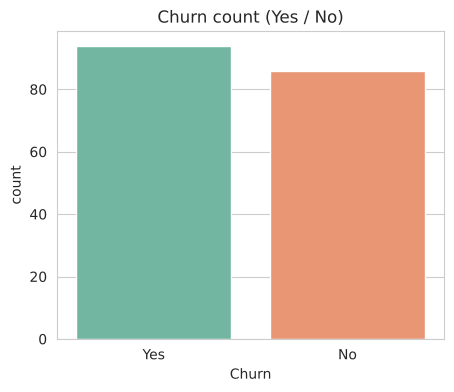

Churn
Yes    94
No     86
Name: count, dtype: int64

Churn
Yes    52.22
No     47.78
Name: proportion, dtype: float64


In [8]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Churn count (Yes / No)')
plt.show()

print(df['Churn'].value_counts())
print()
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

**Observation:**
- 94 customers churned (52.22%) and 86 customers stayed (47.78%).
- The classes are almost **balanced**, so there is no need for oversampling or class weights, and **accuracy is a fair metric** here. I will still check precision, recall, F1 and ROC-AUC.

### 4.2 Distribution of numeric columns
Histograms show how the values of each numeric column are spread.

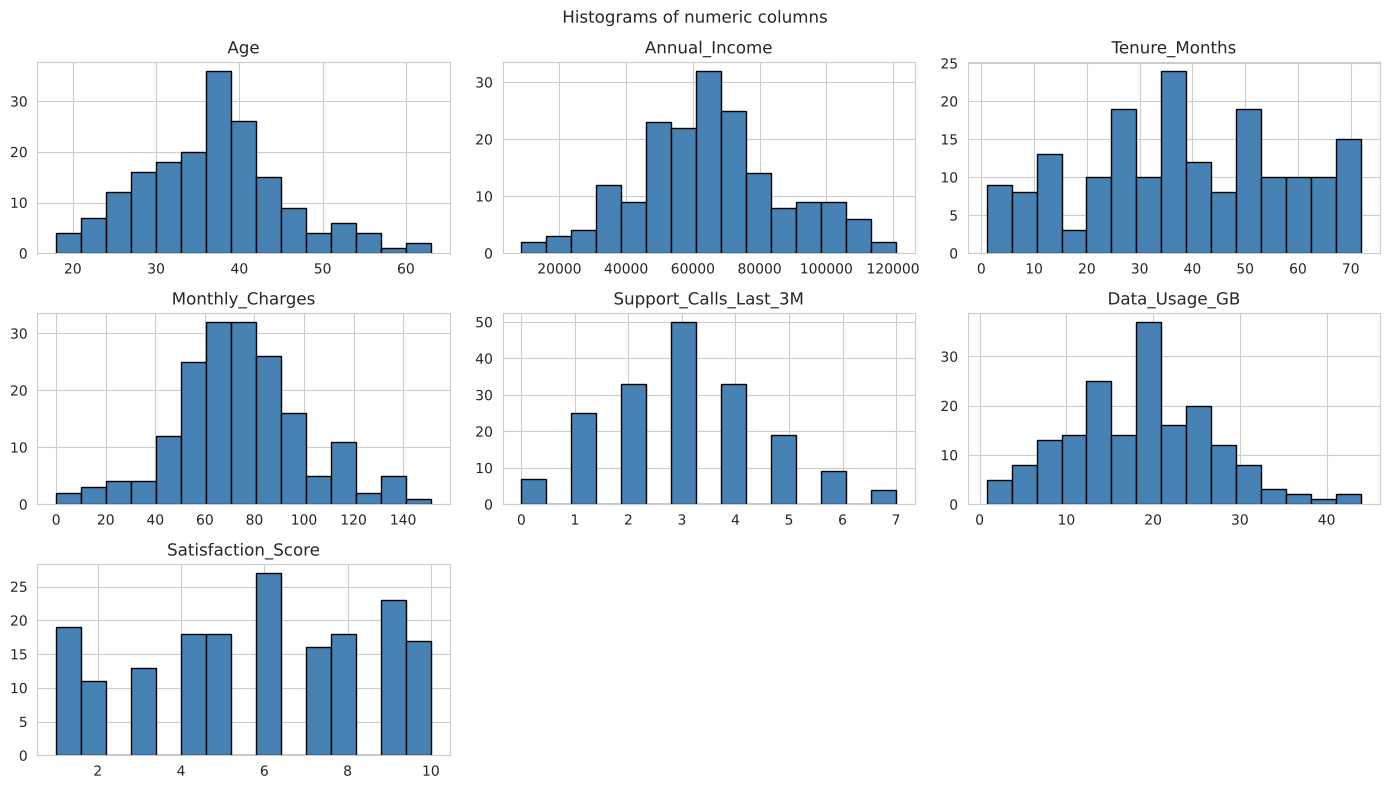

In [9]:
num_cols = ['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges',
            'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']

df[num_cols].hist(bins=15, figsize=(14, 8), color='steelblue', edgecolor='black')
plt.suptitle('Histograms of numeric columns')
plt.tight_layout()
plt.show()

**Observation:**
- **Age** looks like a bell shape with most customers around 35-40 years.
- **Annual_Income** is also bell shaped, most customers earn around 50,000 to 75,000, with a small tail on the right side.
- **Tenure_Months** is spread almost evenly from 1 to 72, so we have both new and old customers.
- **Monthly_Charges** has most values between 60 and 90, with a right tail up to 150.
- **Support_Calls_Last_3M** is mostly 2, 3 or 4 calls. Only a few customers made 0 or 7 calls.
- **Data_Usage_GB** peaks near 20 GB with a small right tail.
- **Satisfaction_Score** is spread from 1 to 10 and does not follow a bell shape.

### 4.3 Numeric columns vs Churn
Boxplots compare the churned and not-churned customers for each numeric column. The table below the plots gives the average values.

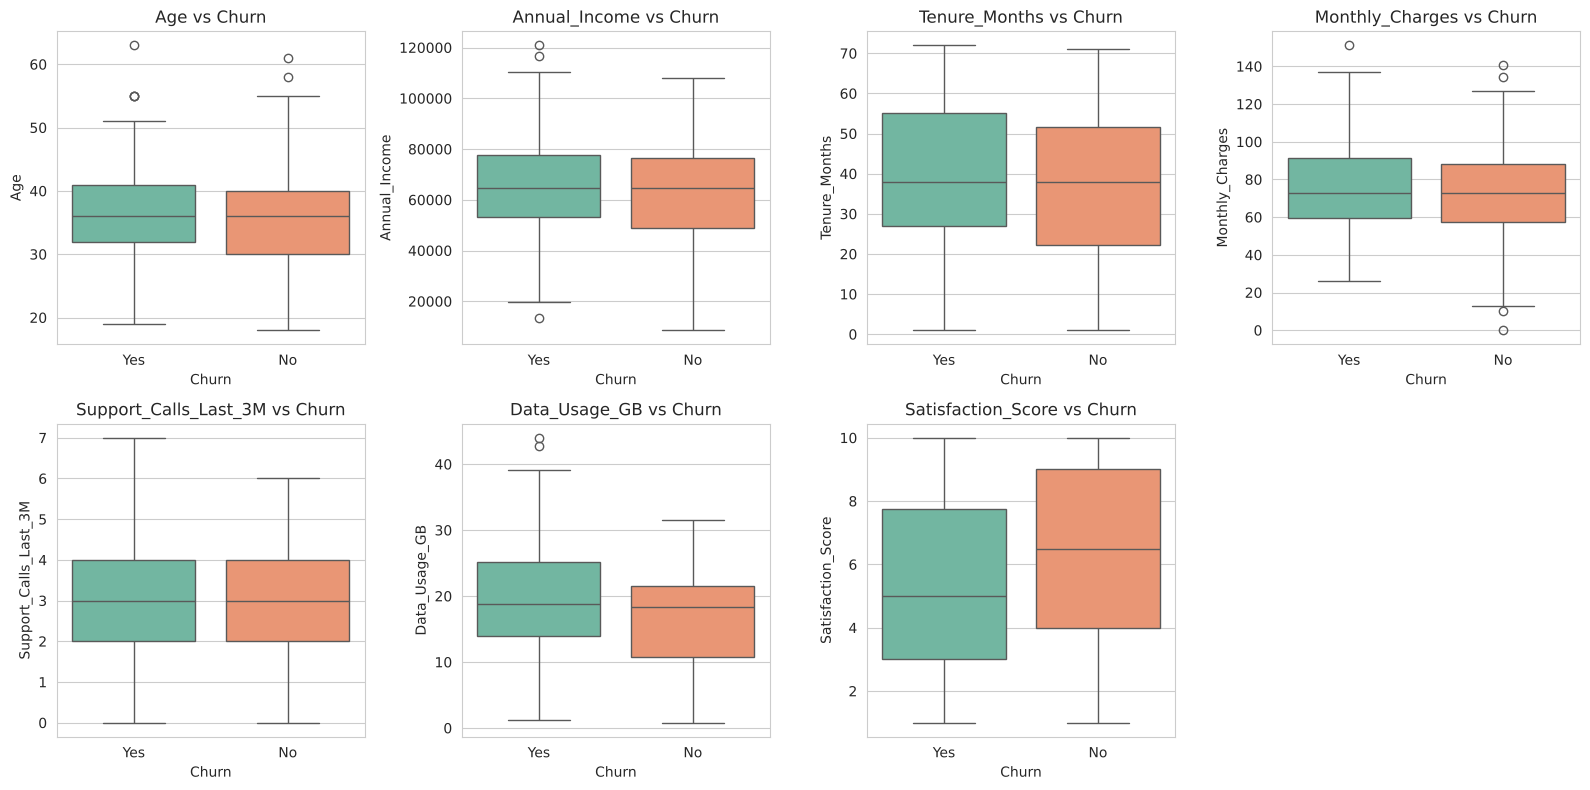

Churn,No,Yes
Age,35.80,36.78
Annual_Income,64223.26,66071.28
Tenure_Months,36.63,40.46
Monthly_Charges,72.65,76.21
Support_Calls_Last_3M,2.95,3.15
Data_Usage_GB,17.12,20.09
Satisfaction_Score,6.30,5.27


In [10]:
plt.figure(figsize=(16, 8))
for i, col in enumerate(num_cols):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(x='Churn', y=col, data=df, palette='Set2')
    plt.title(col + ' vs Churn')
plt.tight_layout()
plt.show()

# average of each numeric column for churn Yes and No
df.groupby('Churn')[num_cols].mean().round(2).T

**Observation:**
- Churned customers have a **lower Satisfaction_Score** (average 5.27 vs 6.30 for customers who stayed). This makes sense, because unhappy customers leave.
- Churned customers use **more data** (20.09 GB vs 17.12 GB) and pay **slightly more** every month (76.21 vs 72.65).
- Churned customers also have a slightly higher tenure (40.46 vs 36.63 months), which is a little surprising because normally old customers stay longer.
- Age, Annual_Income and Support_Calls are almost the same for both groups.
- The boxes of Yes and No overlap a lot in every plot, which means **no single numeric column separates the two classes clearly**. So the models will find this problem difficult.

### 4.4 Categorical columns vs Churn
Count plots show the churn in every category, and the tables give the churn percentage inside each category.

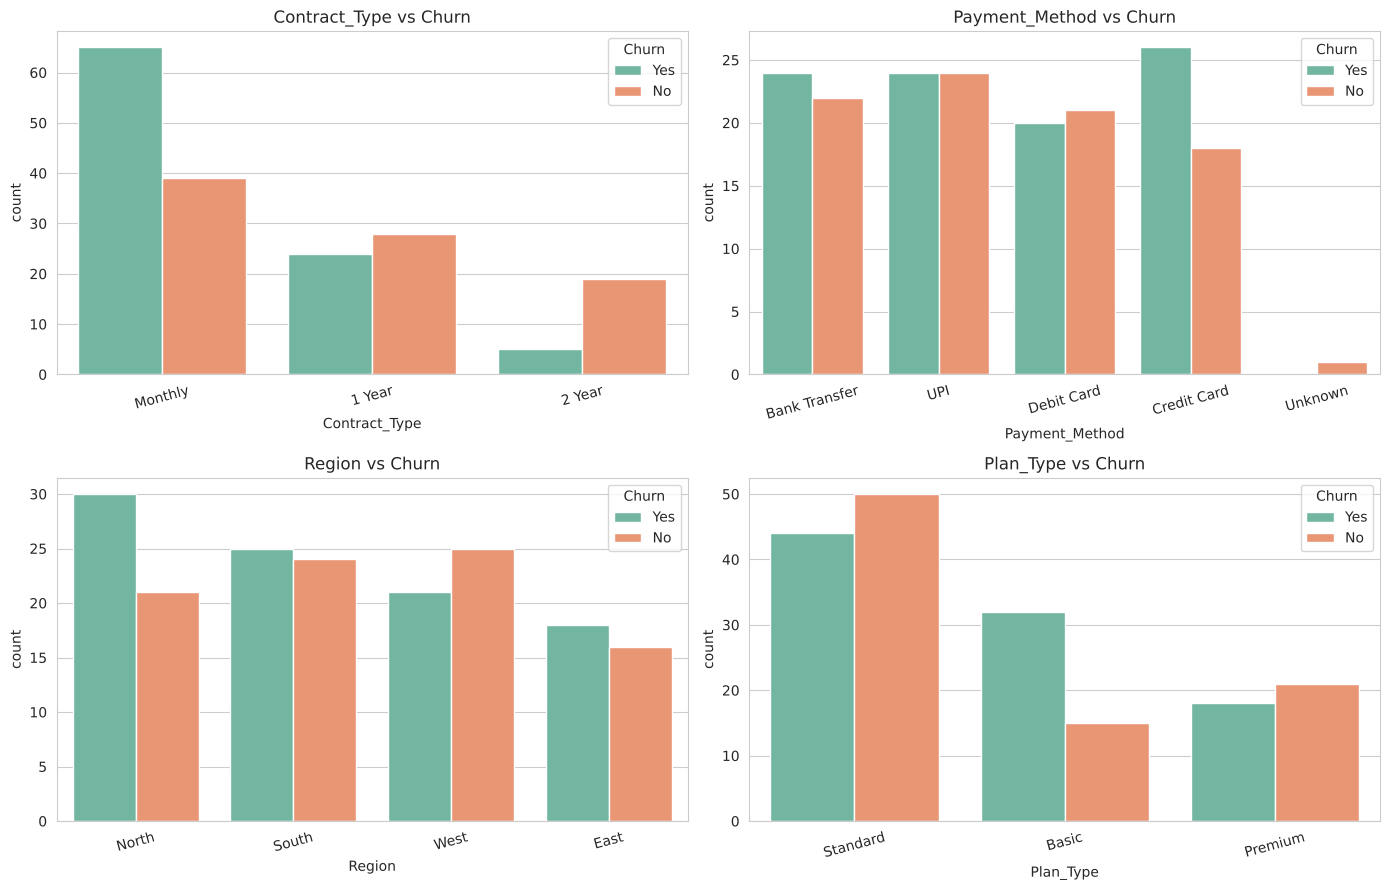

Contract_Type
Churn            No   Yes
Contract_Type            
1 Year         53.8  46.2
2 Year         79.2  20.8
Monthly        37.5  62.5
------------------------------
Payment_Method
Churn              No   Yes
Payment_Method             
Bank Transfer    47.8  52.2
Credit Card      40.9  59.1
Debit Card       51.2  48.8
UPI              50.0  50.0
Unknown         100.0   0.0
------------------------------
Region
Churn     No   Yes
Region            
East    47.1  52.9
North   41.2  58.8
South   49.0  51.0
West    54.3  45.7
------------------------------
Plan_Type
Churn        No   Yes
Plan_Type            
Basic      31.9  68.1
Premium    53.8  46.2
Standard   53.2  46.8
------------------------------


In [11]:
cat_cols = ['Contract_Type', 'Payment_Method', 'Region', 'Plan_Type']

plt.figure(figsize=(14, 9))
for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i + 1)
    sns.countplot(x=col, hue='Churn', data=df, palette='Set2')
    plt.title(col + ' vs Churn')
    plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# churn percentage inside each category
for col in cat_cols:
    print(col)
    print((pd.crosstab(df[col], df['Churn'], normalize='index') * 100).round(1))
    print('-' * 30)

**Observation:**
- **Contract_Type is the strongest pattern.** Churn is 62.5% for Monthly contracts, 46.2% for 1 Year and only 20.8% for 2 Year contracts. Customers with long contracts are much less likely to leave.
- **Plan_Type:** Basic plan customers churn the most (68.1%), whereas Premium (46.2%) and Standard (46.8%) are lower.
- **Region:** North has the highest churn (58.8%) and West the lowest (45.7%), but the difference is small.
- **Payment_Method:** Credit Card is 59.1%, Bank Transfer 52.2%, UPI 50.0% and Debit Card 48.8%. These are close to each other. The 'Unknown' category has just 1 customer, so its 0% churn means nothing.

### 4.5 Correlation heatmap
The correlation shows how strongly each numeric column is related to Churn (1 = Yes, 0 = No). Values near 0 mean almost no linear relationship.

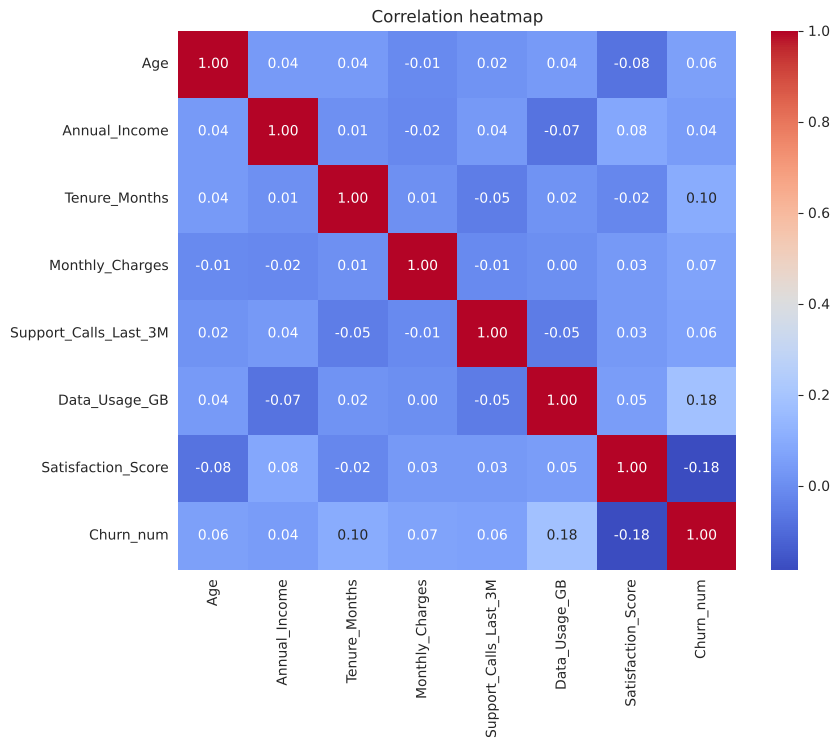

Churn_num                1.000000
Data_Usage_GB            0.182703
Tenure_Months            0.099017
Monthly_Charges          0.068082
Support_Calls_Last_3M    0.061783
Age                      0.057001
Annual_Income            0.042745
Satisfaction_Score      -0.184652
Name: Churn_num, dtype: float64


In [12]:
# for correlation i need churn as a number, so making a temporary column
temp = df.copy()
temp['Churn_num'] = temp['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(9, 7))
sns.heatmap(temp[num_cols + ['Churn_num']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

print(temp[num_cols + ['Churn_num']].corr()['Churn_num'].sort_values(ascending=False))

**Observation:**
- The highest positive correlations with Churn are Data_Usage_GB (+0.18) and Tenure_Months (+0.10). The only negative one is Satisfaction_Score (-0.18).
- All the other columns are below 0.07, which is nearly zero.
- All correlations are **weak** (none is above 0.2). This tells me that the data does not have a strong signal, so i should not expect very high accuracy from the models (maybe 60-75%).
- Only Satisfaction_Score and Data_Usage_GB are somewhat useful, along with Contract_Type and Plan_Type that we saw in the earlier plots.

## Step 5: Data preprocessing

Steps done here:
1. Remove `Customer_ID` because it is just an ID and does not help in prediction.
2. Convert `Churn` to numbers (Yes = 1, No = 0).
3. Convert the 4 categorical columns to numbers with **one-hot encoding** (`get_dummies`). I used `drop_first=True` to remove one extra column in each category, so that the columns are not repeating the same information.

In [13]:
# 1) Customer_ID is just an id, it has no use for prediction so dropping it
data = df.drop('Customer_ID', axis=1)

# 2) converting target column Churn into numbers: Yes = 1, No = 0
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

# 3) converting the text columns into numbers using one-hot encoding
data = pd.get_dummies(data, columns=['Contract_Type', 'Payment_Method', 'Region', 'Plan_Type'],
                      drop_first=True, dtype=int)

print('Shape after encoding:', data.shape)
print()
print(list(data.columns))
data.head()

Shape after encoding:

 (180, 19)

['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Churn', 'Contract_Type_2 Year', 'Contract_Type_Monthly', 'Payment_Method_Credit Card', 'Payment_Method_Debit Card', 'Payment_Method_UPI', 'Payment_Method_Unknown', 'Region_North', 'Region_South', 'Region_West', 'Plan_Type_Premium', 'Plan_Type_Standard']


,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Churn,Contract_Type_2 Year,Contract_Type_Monthly,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_UPI,Payment_Method_Unknown,Region_North,Region_South,Region_West,Plan_Type_Premium,Plan_Type_Standard
0,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,1,0,1,0,0,0,0,1,0,0,0,1
1,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,1,0,1,0,0,0,0,0,1,0,0,0
2,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,1,0,1,0,0,1,0,0,0,1,0,0
3,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,1,0,1,0,0,1,0,0,1,0,0,1
4,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,1,0,1,0,1,0,0,0,0,1,1,0


**Observation:**
- After encoding the dataset has **19 columns**: 18 input features and 1 target (Churn).
- New columns like `Contract_Type_Monthly`, `Plan_Type_Premium`, `Region_North` etc. contain 0 or 1. For example, the category dropped for Contract_Type is '1 Year', so a customer with 0 in both `Contract_Type_Monthly` and `Contract_Type_2 Year` is a 1 Year customer.
- Now all the columns are numeric, so the data can go into the neural networks.

### Train-test split
I split the data into 80% training and 20% testing. The test data is kept away and used only at the end for final evaluation. `stratify=y` keeps the same Yes/No ratio in both parts.

In [14]:
X = data.drop('Churn', axis=1)
y = data['Churn']

# 80% training and 20% testing. stratify keeps the Yes/No ratio same in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('Churn ratio in train:', y_train.mean().round(3), ' | in test:', y_test.mean().round(3))

X_train: (144, 18)  X_test: (36, 18)
Churn ratio in train: 0.521  | in test: 0.528


**Observation:**
- Training data has 144 rows and test data has 36 rows, each with 18 features.
- The churn ratio is 0.521 in train and 0.528 in test, so both parts have a similar class balance.
- **Important point:** the test set is only 36 customers, so one customer is about 2.8% of accuracy. The final scores will be a little unstable because of this.

### Feature scaling
I use `StandardScaler` which makes every column have mean 0 and standard deviation 1. The scaler is **fitted only on the training data** and then applied to the test data. If we fit on the full data, information from test data leaks into training (data leakage).

In [15]:
# scaling is needed because Annual_Income is in ten thousands but Support_Calls is in single digits
# fit only on train data, then use the same scaler on test data (so no data leakage)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print('Mean of first 3 scaled train columns:', X_train_sc[:, :3].mean(axis=0).round(3))
print('Std  of first 3 scaled train columns:', X_train_sc[:, :3].std(axis=0).round(3))

Mean of first 3 scaled train columns: [ 0. -0. -0.]
Std  of first 3 scaled train columns: [1. 1. 1.]


**Observation:** After scaling, the mean of the training columns is 0 and the standard deviation is 1. Now Annual_Income (in thousands) and Support_Calls (single digits) are on the same scale, so no feature dominates the others and the neural network can train faster and in a stable way.

## Step 6: Helper functions

All three models need the same things: draw the training curves and calculate the test results. So i wrote two small functions once and will reuse them, instead of copying the same code three times.

- `plot_history()` plots the training and validation loss/accuracy.
- `evaluate_model()` predicts on the test data (threshold 0.5), prints accuracy, precision, recall, F1, ROC-AUC, the classification report, draws the confusion matrix, and saves the scores for the final comparison.

In [16]:
# these two functions are used for all three models so i dont have to write the same code again and again

results = []          # to store the final scores of every model
roc_data = {}         # to store roc curve points of every model

def plot_history(history, title):
    """plots loss and accuracy curves of training and validation"""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['loss'], label='Train loss')
    ax[0].plot(history.history['val_loss'], label='Validation loss')
    ax[0].set_title(title + ' - Loss')
    ax[0].set_xlabel('Epoch')
    ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='Train accuracy')
    ax[1].plot(history.history['val_accuracy'], label='Validation accuracy')
    ax[1].set_title(title + ' - Accuracy')
    ax[1].set_xlabel('Epoch')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

def evaluate_model(model, X_t, y_t, name):
    """predicts on test data, prints metrics, draws confusion matrix and saves the scores"""
    prob = model(X_t, training=False).numpy().ravel()
    pred = (prob >= 0.5).astype(int)

    acc = accuracy_score(y_t, pred)
    prec = precision_score(y_t, pred, zero_division=0)
    rec = recall_score(y_t, pred, zero_division=0)
    f1 = f1_score(y_t, pred, zero_division=0)
    auc = roc_auc_score(y_t, prob)

    print(name, 'results on test data')
    print('Accuracy :', round(acc, 4))
    print('Precision:', round(prec, 4))
    print('Recall   :', round(rec, 4))
    print('F1-score :', round(f1, 4))
    print('ROC-AUC  :', round(auc, 4))
    print()
    print(classification_report(y_t, pred, target_names=['No churn', 'Churn'], zero_division=0))

    plt.figure(figsize=(4, 3.5))
    sns.heatmap(confusion_matrix(y_t, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['No churn', 'Churn'], yticklabels=['No churn', 'Churn'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(name + ' - Confusion matrix')
    plt.show()

    fpr, tpr, _ = roc_curve(y_t, prob)
    roc_data[name] = (fpr, tpr, auc)
    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1, 'ROC-AUC': auc})

**Explanation:** This cell has no output because it only defines the functions. The model gives a probability between 0 and 1; if it is 0.5 or more we treat it as Churn = 1, otherwise 0. The scores are stored in the `results` list and the ROC points in `roc_data`, which we use in Step 9.

## Step 6: ANN (Artificial Neural Network)

**What is ANN?** It is the basic neural network made of fully connected (Dense) layers. Every neuron of one layer is connected to all neurons of the next layer. It is the most natural choice for tabular data like ours.

**My architecture**
- Input layer: 18 features
- Dense(32, relu) -> Dropout(0.3)
- Dense(16, relu) -> Dropout(0.3)
- Output: Dense(1, sigmoid), which gives the churn probability

**Why these choices?**
- *ReLU* is the usual activation for hidden layers. *Sigmoid* is used at the output because we have 2 classes.
- *Dropout* randomly switches off 30% of neurons while training, which reduces overfitting. This is important because we have just 144 training rows.
- *Adam* optimizer with learning rate 0.001 and *binary cross-entropy* loss, since it is binary classification.

In [17]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

ann = keras.Sequential([
    layers.Input(shape=(X_train_sc.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')     # sigmoid because it is binary (yes/no) output
], name='ANN')

ann.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

ann.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

**Observation:** The summary shows the ANN has about **1,153 trainable parameters**. 18 inputs x 32 neurons + 32 biases = 608 parameters in the first layer, 528 in the second and 17 in the output layer. This is a small network, which is suitable because the dataset is also small. A big network would just memorize 144 rows.

### Training the ANN
I use `validation_split=0.2` so 20% of the training data is used as validation data to watch the overfitting. `EarlyStopping` stops the training when validation loss does not improve for 20 epochs and gets back the best weights.

Training stopped at epoch: 70
Best validation loss: 0.6013


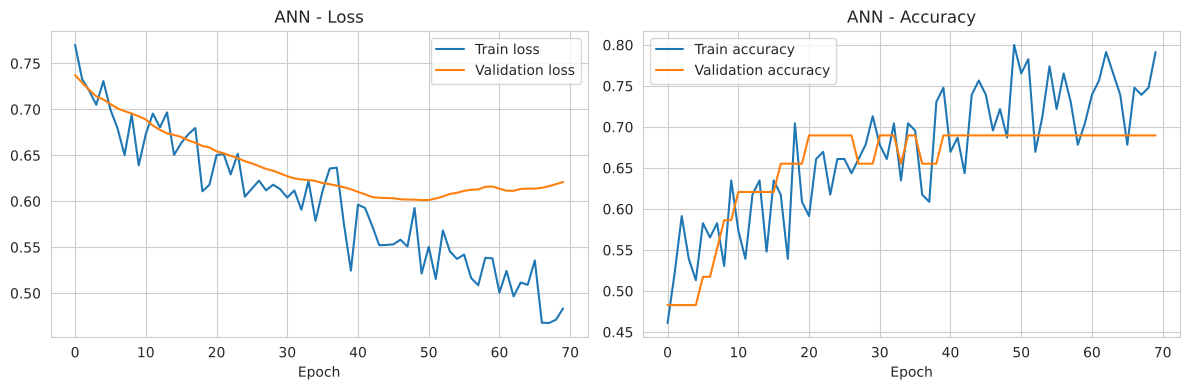

In [18]:
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

ann_history = ann.fit(X_train_sc, y_train.values,
                      validation_split=0.2,
                      epochs=150,
                      batch_size=16,
                      callbacks=[early_stop],
                      verbose=0)

print('Training stopped at epoch:', len(ann_history.history['loss']))
print('Best validation loss:', round(min(ann_history.history['val_loss']), 4))
plot_history(ann_history, 'ANN')

**Observation:**
- Training stopped at epoch 70 (i gave a maximum of 150), and the best validation loss was **0.6013**.
- In the loss graph the training loss keeps falling to around 0.48, but the validation loss reaches its minimum near epoch 50 and then starts to go up slowly. This is the beginning of **overfitting**, and early stopping handled it by restoring the best weights from that point.
- The validation accuracy is flat around 69%, while the training accuracy is noisy and goes up to nearly 80%. The gap between them again shows a small amount of overfitting.

### Testing the ANN
Now the trained ANN is evaluated on the unseen test data (36 customers).

ANN results on test data
Accuracy : 0.6389
Precision: 0.6875
Recall   : 0.5789
F1-score : 0.6286
ROC-AUC  : 0.6161

              precision    recall  f1-score   support

    No churn       0.60      0.71      0.65        17
       Churn       0.69      0.58      0.63        19

    accuracy                           0.64        36
   macro avg       0.64      0.64      0.64        36
weighted avg       0.65      0.64      0.64        36



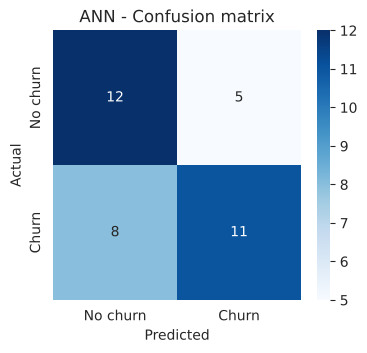

In [19]:
evaluate_model(ann, X_test_sc, y_test.values, 'ANN')

**Observation:**
- **Accuracy = 63.89%**, Precision = 0.6875, Recall = 0.5789, F1 = 0.6286, ROC-AUC = 0.6161.
- From the confusion matrix: 12 non-churn customers were correctly predicted, 5 were wrongly predicted as churn, 11 churners were correctly caught and 8 churners were missed.
- Recall for churn is only 58%, which means the ANN misses about 4 out of every 10 customers who actually leave. In a real company this is costly, because we want to catch the leaving customers.
- The model is better than random guessing (50%) but not very strong. This matches the weak correlations that we saw in the EDA.

## Step 7: CNN (Convolutional Neural Network)

**What is CNN?** A CNN uses convolution filters that slide over the input and detect local patterns. It is mostly used for images, but a **1D CNN** can work on sequences or on tabular data by treating the columns as a line of values.

**Reshaping the data:** Conv1D layer needs a 3D input of shape (samples, steps, channels). Our data is 2D (144, 18), so i reshape it to (144, 18, 1), which means 18 steps with 1 value each.

In [20]:
# CNN and RNN need 3D input: (samples, time steps, features per step)
# our data is tabular so i am treating every column as one "step" with a single value
X_train_seq = X_train_sc.reshape(X_train_sc.shape[0], X_train_sc.shape[1], 1)
X_test_seq = X_test_sc.reshape(X_test_sc.shape[0], X_test_sc.shape[1], 1)

print('Before reshape:', X_train_sc.shape)
print('After reshape :', X_train_seq.shape)

Before reshape: (144, 18)
After reshape : (144, 18, 1)


**Observation:** The shape changed from (144, 18) to (144, 18, 1). The numbers are the same, only an extra dimension is added. The same reshaped data will be used for the RNN also.

### CNN architecture
- Conv1D(32 filters, kernel size 3, relu) -> MaxPooling1D(2)
- Conv1D(16 filters, kernel size 3, relu)
- Flatten -> Dense(16, relu) -> Dropout(0.3)
- Output: Dense(1, sigmoid)

*Conv1D* filters look at 3 neighbouring features at a time, *MaxPooling* reduces the length by half, and *Flatten* converts the output into one long vector for the Dense layers.

**Note:** In my first try i used `GlobalMaxPooling1D` instead of `Flatten`. That model did not learn at all: it stopped after about 16 epochs and predicted almost every customer as 'churn' (test accuracy was 50%). GlobalMaxPooling keeps only the maximum value of each filter and throws away the position of the feature, which is a problem here because every column has a different meaning. So i changed it to `Flatten`, and i chose this using the validation loss, not the test data.

In [21]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

cnn = keras.Sequential([
    layers.Input(shape=(X_train_seq.shape[1], 1)),
    layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=16, kernel_size=3, activation='relu', padding='same'),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name='CNN')

cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 18, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 9, 16)          │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 144)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,017 (15.69 KB)

 Trainable params: 4,017 (15.69 KB)

 Non-trainable params: 0 (0.00 B)

**Observation:** The CNN has about **4,017 trainable parameters**, which is more than the ANN, and the Conv1D layers keep the output length as 18 and then 9 after pooling (padding='same'). One thing to remember is that a CNN assumes that neighbouring values are related to each other (like pixels in an image). In our table, columns like Age and Annual_Income sitting next to each other have no special relation, so the CNN does not have a real advantage here.

### Training the CNN
Same settings as the ANN (validation split 20%, batch size 16, EarlyStopping with patience 20).

Training stopped at epoch: 32
Best validation loss: 0.6244


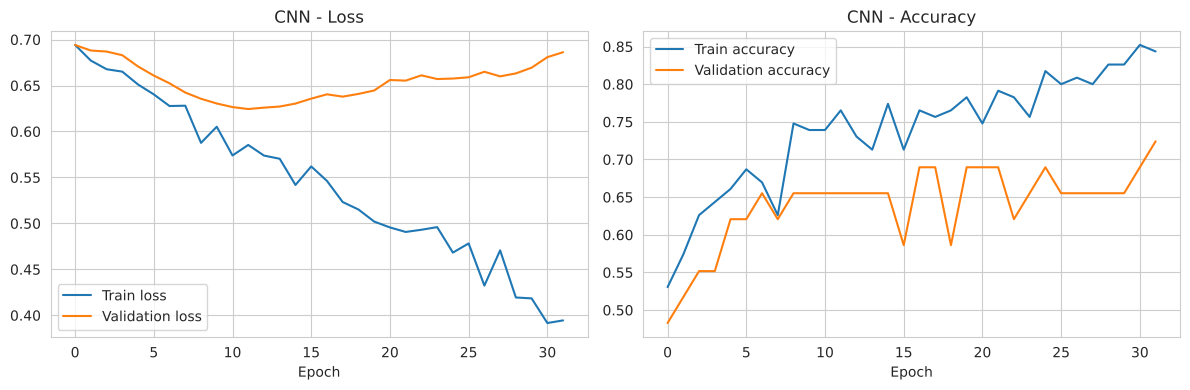

In [22]:
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

cnn_history = cnn.fit(X_train_seq, y_train.values,
                      validation_split=0.2,
                      epochs=150,
                      batch_size=16,
                      callbacks=[early_stop],
                      verbose=0)

print('Training stopped at epoch:', len(cnn_history.history['loss']))
print('Best validation loss:', round(min(cnn_history.history['val_loss']), 4))
plot_history(cnn_history, 'CNN')

**Observation:**
- Training stopped at epoch 32 and the best validation loss was **0.6244**, which is higher (worse) than the ANN's 0.6013.
- The validation loss is lowest around epoch 12 and then increases, while the training loss keeps decreasing to about 0.39. So the CNN **overfits faster than the ANN**, which makes sense because it has more parameters for the same 144 rows.
- Training accuracy reaches about 85% but validation accuracy stays between 60-72%.

### Testing the CNN

CNN results on test data
Accuracy : 0.5556
Precision: 0.5882
Recall   : 0.5263
F1-score : 0.5556
ROC-AUC  : 0.6378

              precision    recall  f1-score   support

    No churn       0.53      0.59      0.56        17
       Churn       0.59      0.53      0.56        19

    accuracy                           0.56        36
   macro avg       0.56      0.56      0.56        36
weighted avg       0.56      0.56      0.56        36



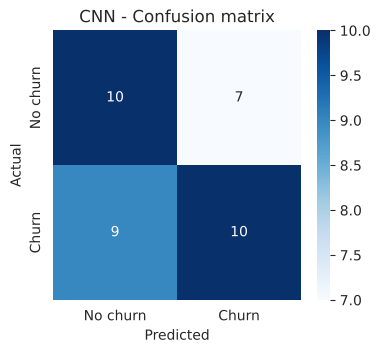

In [23]:
evaluate_model(cnn, X_test_seq, y_test.values, 'CNN')

**Observation:**
- **Accuracy = 55.56%**, Precision = 0.5882, Recall = 0.5263, F1 = 0.5556, ROC-AUC = 0.6378.
- Confusion matrix: 10 non-churn correct, 7 wrongly predicted as churn, 10 churners caught and 9 churners missed.
- This is the **lowest accuracy** of the three models and only a bit above random guessing (50%).
- Interesting point: its ROC-AUC (0.6378) is actually higher than the ANN's (0.6161). This means the CNN ranks the customers reasonably well, but the 0.5 cut-off is not working well for it.
- As expected, the CNN is not a good fit for this kind of tabular data.

## Step 8: RNN (Recurrent Neural Network)

**What is RNN?** An RNN reads the input one step at a time and keeps a memory (hidden state) of the previous steps, so it is made for sequence data like text, time series etc. Here i use `SimpleRNN`, and the 18 features are fed as 18 time steps (same reshaped data as the CNN).

**Architecture**
- SimpleRNN(32, tanh) -> Dropout(0.3)
- Dense(16, relu)
- Output: Dense(1, sigmoid)

`tanh` is the default activation for RNN. The RNN reads the 18 features one by one and the final hidden state (32 values) is used for the prediction.

In [24]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

rnn = keras.Sequential([
    layers.Input(shape=(X_train_seq.shape[1], 1)),
    layers.SimpleRNN(32, activation='tanh'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name='RNN')

rnn.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

rnn.summary()

Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

**Observation:** The RNN has **1,633 trainable parameters**. The SimpleRNN layer alone has 1,088 parameters (it has weights for the input, for the previous hidden state, and the bias). Our data is not a real time series, so the 'order' of the columns is just the order in the file. This is a limitation of using an RNN here, and i should mention it in the conclusion.

### Training the RNN

Training stopped at epoch: 38
Best validation loss: 0.6321


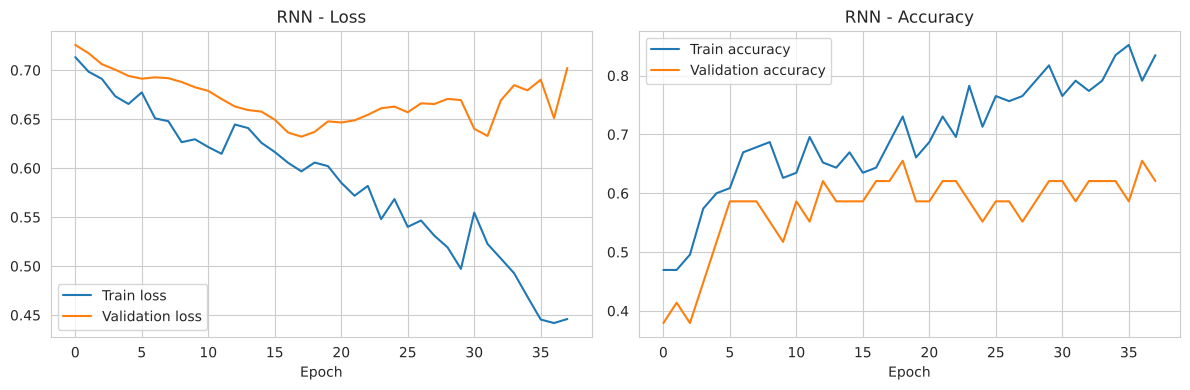

In [25]:
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

rnn_history = rnn.fit(X_train_seq, y_train.values,
                      validation_split=0.2,
                      epochs=150,
                      batch_size=16,
                      callbacks=[early_stop],
                      verbose=0)

print('Training stopped at epoch:', len(rnn_history.history['loss']))
print('Best validation loss:', round(min(rnn_history.history['val_loss']), 4))
plot_history(rnn_history, 'RNN')

**Observation:**
- Training stopped at epoch 38 and the best validation loss was **0.6321**.
- The validation loss is lowest around epoch 17, then it becomes unstable and goes up, while the training loss keeps falling to about 0.44. So the RNN also overfits after some epochs.
- The validation accuracy is only about 55-65%, and the curve is jumpy. This shows that RNN training on a small dataset is not very stable.

### Testing the RNN

RNN results on test data
Accuracy : 0.6944
Precision: 0.7222
Recall   : 0.6842
F1-score : 0.7027
ROC-AUC  : 0.6749

              precision    recall  f1-score   support

    No churn       0.67      0.71      0.69        17
       Churn       0.72      0.68      0.70        19

    accuracy                           0.69        36
   macro avg       0.69      0.70      0.69        36
weighted avg       0.70      0.69      0.69        36



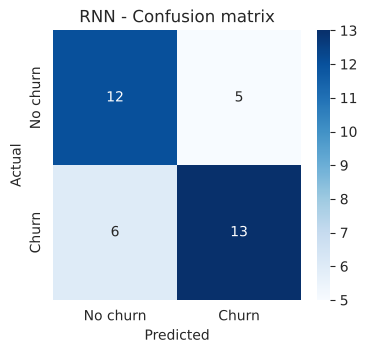

In [26]:
evaluate_model(rnn, X_test_seq, y_test.values, 'RNN')

**Observation:**
- **Accuracy = 69.44%**, Precision = 0.7222, Recall = 0.6842, F1 = 0.7027, ROC-AUC = 0.6749.
- Confusion matrix: 12 non-churn correct, 5 wrongly predicted as churn, 13 churners caught and 6 churners missed.
- This is the **best result** among the three models on the test set, in accuracy, recall, F1 and AUC.
- But i need to be careful: the RNN had the *highest* validation loss during training (0.6321), and the test set has only 36 rows, so this result could be partly due to luck of the split.

## Step 9: Comparison of ANN, CNN and RNN

All the scores are collected in one table.

In [27]:
results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
ANN,0.6389,0.6875,0.5789,0.6286,0.6161
CNN,0.5556,0.5882,0.5263,0.5556,0.6378
RNN,0.6944,0.7222,0.6842,0.7027,0.6749


**Observation:**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| ANN | 0.6389 | 0.6875 | 0.5789 | 0.6286 | 0.6161 |
| CNN | 0.5556 | 0.5882 | 0.5263 | 0.5556 | 0.6378 |
| RNN | 0.6944 | 0.7222 | 0.6842 | 0.7027 | 0.6749 |

- RNN is first in accuracy, precision, recall, F1 and ROC-AUC. ANN is second in accuracy and CNN is last.
- The difference between ANN and RNN is only 2 customers out of 36 (23 vs 25 correct predictions), so it is not a big or very reliable difference.

### Visual comparison
A bar chart of all metrics and the ROC curves of the three models.

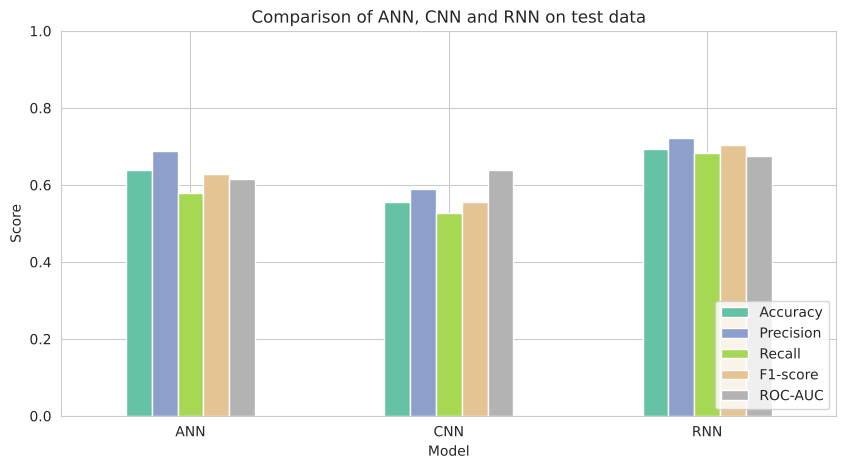

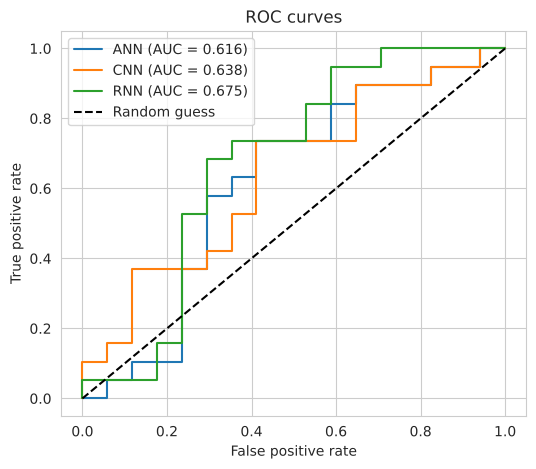

In [28]:
results_df[['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5), colormap='Set2')
plt.title('Comparison of ANN, CNN and RNN on test data')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

plt.figure(figsize=(6, 5))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=name + ' (AUC = ' + str(round(auc, 3)) + ')')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves')
plt.legend()
plt.show()

**Observation:**
- In the bar chart the RNN bars are the highest for most metrics and the CNN bars are the lowest, except ROC-AUC where the CNN is above the ANN.
- In the ROC curves all three curves are only a little above the diagonal dotted line (random guess). A model with AUC 1.0 would be perfect and 0.5 would be random, and our models are in 0.62 to 0.67, which means weak to moderate prediction power.
- This again confirms the weak signal in the data that we noticed in the EDA.

## Step 10: Conclusion

**What i did:** I loaded the churn dataset (180 customers), checked its quality, did EDA, encoded and scaled the data, and then built three deep learning models, ANN, 1D-CNN and SimpleRNN, and compared them on the same train/test split.

**Main findings from EDA**
- The data is clean (no missing values or duplicates) and the classes are balanced (52% churn, 48% no churn).
- Churn is related most to 
**Contract_Type** (Monthly 62.5% vs 2 Year only 20.8%), 
**Plan_Type** (Basic plan 68.1%) and 
**Satisfaction_Score** (low satisfaction means more churn).
- Overall the correlations are weak, so the problem is hard.

**Model results (test accuracy)**
- ANN: 63.89%
- CNN: 55.56%
- RNN: 69.44% (best on this test split)

**Final comments**
1. The RNN scored the highest, but the difference from the ANN is only 2 customers out of 36, so i cannot say strongly that the RNN is better. If i change the random seed or the split, the order may change.
2. The ANN is the most natural and simple model for tabular data like this. CNN and RNN are made for images and sequences, and our columns have no spatial or time order. I used them because the assignment asked for it, but they have no real advantage here.
3. All models overfit after some epochs (training loss went down while validation loss went up). Dropout and early stopping reduced it, but the main reason is the small dataset.
4. Accuracy of 55-70% is not very high. The reasons are the small data (only 144 rows for training) and the weak relation between features and churn.

**Limitations and future work**
- Collect more customer data; deep learning needs far more rows than 180.
- Use k-fold cross-validation so that the result does not depend on one 36-row test set.
- Try traditional models like Logistic Regression or Random Forest, which usually work better on small tabular data, and compare them with these networks.
- Try feature engineering and tune hyperparameters (layers, neurons, learning rate, dropout).